In [1]:
import sys

sys.path.append('../src')

In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt

import tensor_utils
import projectors
import loggers

In [14]:
# x_0 = torch.randn((32, 32, 32))
# x_0 = torch.randn((16, 16, 16, 16))

# x_0 = torch.randn((3, 128, 128))
x_0 = torch.randn((3, 3, 128, 128))

D = x_0.dim()

In [15]:
proj_results = projectors.dykstra(x_0, 
                                  projector=projectors.project_spectral_ball, 
                                  num_sets=D, 
                                  max_iter=250, 
                                  tol=1e-6)

# proj_results = projectors.dykstra(x_0, 
#                                   projector=projectors.project_spectral_sphere, 
#                                   num_sets=2, 
#                                   max_iter=2500, 
#                                   tol=1e-6)

proj_results.keys()

print(f"Converged: {proj_results['converged']}")
print(f"Iterations: {proj_results['iterations']:4}")

Converged: False
Iterations:  250


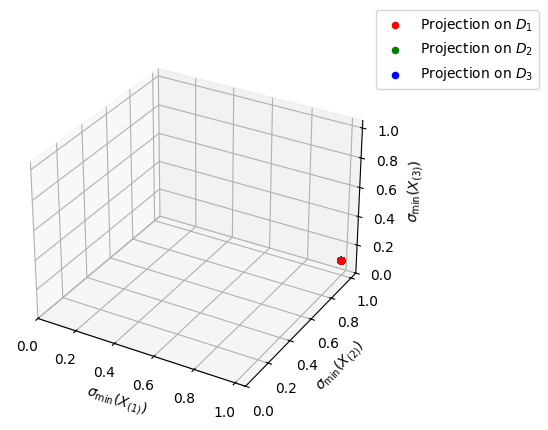

In [16]:
import matplotlib.pyplot as plt

proj_history = proj_results['history']

# Create a figure and a 3D axis
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')  # :cite[3]:cite[4]

# Plot your data as a 3D curve
ax.plot(proj_history['min_sigvals'][0], proj_history['min_sigvals'][1], proj_history['min_sigvals'][2])  # :cite[2]:cite[4]
ax.scatter3D(proj_history['min_sigvals'][0][0::D], proj_history['min_sigvals'][1][0::D], proj_history['min_sigvals'][2][0::D], c='r', label=r'Projection on $D_1$')
ax.scatter3D(proj_history['min_sigvals'][0][1::D], proj_history['min_sigvals'][1][1::D], proj_history['min_sigvals'][2][1::D], c='g', label=r'Projection on $D_2$')
ax.scatter3D(proj_history['min_sigvals'][0][2::D], proj_history['min_sigvals'][1][2::D], proj_history['min_sigvals'][2][2::D], c='b', label=r'Projection on $D_3$')

# Add labels to make the plot clear
ax.set_xlabel(r'$\sigma_\min (X_{(1)})$')
ax.set_ylabel(r'$\sigma_\min (X_{(2)})$')
ax.set_zlabel(r'$\sigma_\min (X_{(3)})$')

ax.set_xlim((0, 1.05))
ax.set_ylim((0, 1.05))
ax.set_zlim((0, 1.05))

plt.legend(loc='upper right', bbox_to_anchor=(1.45, 1.1))

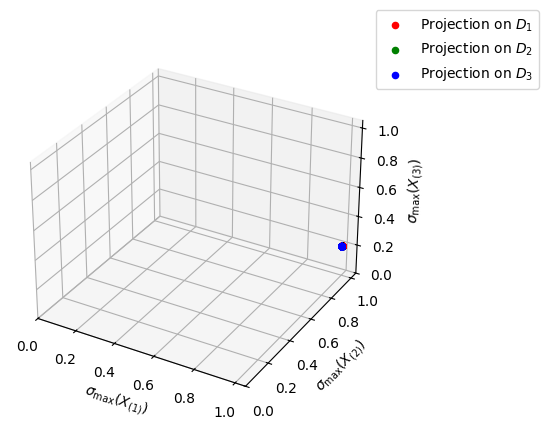

In [17]:
import matplotlib.pyplot as plt

proj_history = proj_results['history']

# Create a figure and a 3D axis
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')  # :cite[3]:cite[4]

# Plot your data as a 3D curve
ax.plot(proj_history['max_sigvals'][0], proj_history['max_sigvals'][1], proj_history['max_sigvals'][2])  # :cite[2]:cite[4]
ax.scatter3D(proj_history['max_sigvals'][0][0::D], proj_history['max_sigvals'][1][0::D], proj_history['max_sigvals'][2][0::D], c='r', label=r'Projection on $D_1$')
ax.scatter3D(proj_history['max_sigvals'][0][1::D], proj_history['max_sigvals'][1][1::D], proj_history['max_sigvals'][2][1::D], c='g', label=r'Projection on $D_2$')
ax.scatter3D(proj_history['max_sigvals'][0][2::D], proj_history['max_sigvals'][1][2::D], proj_history['max_sigvals'][2][2::D], c='b', label=r'Projection on $D_3$')

# Add labels to make the plot clear
ax.set_xlabel(r'$\sigma_\max (X_{(1)})$')
ax.set_ylabel(r'$\sigma_\max (X_{(2)})$')
ax.set_zlabel(r'$\sigma_\max (X_{(3)})$')

ax.set_xlim((0, 1.05))
ax.set_ylim((0, 1.05))
ax.set_zlim((0, 1.05))

plt.legend(loc='upper right', bbox_to_anchor=(1.45, 1.1))

In [18]:
x_proj = proj_results['projection']

In [23]:
torch.linalg.svdvals(
    tensor_utils.unfold(x_proj, 0)
)

tensor([0.9991, 0.9991, 0.9991])

In [37]:
x_proj_one = projectors.project_spectral_ball(
    x_0, idx=0
)

# x_proj_one = projectors.project_spectral_ball(
#     x_proj_one, idx=1
# )

In [42]:
torch.linalg.svdvals(
    tensor_utils.unfold(x_proj, 0)
)

tensor([0.9991, 0.9991, 0.9991])

In [33]:
f"{torch.linalg.norm(x_proj - x_proj_one):.2e}"

'6.36e-03'

In [43]:
(x_0 * x_proj).sum()

tensor(663.9952)

In [44]:
(x_0 * x_proj_one).sum()

tensor(664.6251)